In [2]:

print("Welcome to Mobile Battery Usage Analysis")
print("Project Started Successfully!")
print("We are using Python in Google Colab")


Welcome to Mobile Battery Usage Analysis
Project Started Successfully!
We are using Python in Google Colab


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [6]:

data = {
    'Date': [
        '2026-11-01', '2026-11-01',
        '2026-11-01', '2026-11-01',
        '2026-11-02', '2026-11-02',
        '2026-11-02', '2026-11-02',
        '2026-11-03', '2026-11-03',
        '2026-11-03', '2026-11-03',
        '2026-11-04', '2026-11-04',
        '2026-11-04', '2026-11-04',
        '2026-11-05', '2026-11-05',
        '2026-11-05', '2026-11-05'
    ],

    'App': [
        'Instagram', 'YouTube', 'WhatsApp', 'Chrome',
        'Instagram', 'YouTube', 'WhatsApp', 'Spotify',
        'Instagram', 'YouTube', 'Camera', 'Chrome',
        'Instagram', 'WhatsApp', 'YouTube', 'Spotify',
        'Instagram', 'YouTube', 'WhatsApp', 'Camera'
    ],

    'Screen_Time_Min': [
        120, 90, 45, 30, 100, 110, 60, 80,
        130, 95, 20, 40, 115, 50, 100, 75,
        140, 105, 55, 25
    ],

    'Battery_Usage': [
        25, 22, 8, 7, 23, 27, 10, 12,
        28, 24, 9, 8, 24, 9, 25, 11,
        30, 26, 10, 10
    ],

    'Battery_Start': [
        100, 75, 53, 45, 95, 72, 45, 35,
        90, 62, 38, 29, 85, 61, 52, 41,
        90, 60, 34, 24
    ],

    'Battery_End': [
        75, 53, 45, 38, 72, 45, 35, 23,
        62, 38, 29, 21, 61, 52, 27, 30,
        60, 34, 24, 14
    ]
}

df = pd.DataFrame(data)

print("Dataset Created Successfully!")


Dataset Created Successfully!


In [8]:

print(df)


          Date        App  Screen_Time_Min  Battery_Usage  Battery_Start  \
0   2026-11-01  Instagram              120             25            100   
1   2026-11-01    YouTube               90             22             75   
2   2026-11-01   WhatsApp               45              8             53   
3   2026-11-01     Chrome               30              7             45   
4   2026-11-02  Instagram              100             23             95   
5   2026-11-02    YouTube              110             27             72   
6   2026-11-02   WhatsApp               60             10             45   
7   2026-11-02    Spotify               80             12             35   
8   2026-11-03  Instagram              130             28             90   
9   2026-11-03    YouTube               95             24             62   
10  2026-11-03     Camera               20              9             38   
11  2026-11-03     Chrome               40              8             29   
12  2026-11-

In [10]:

print(df.head())


         Date        App  Screen_Time_Min  Battery_Usage  Battery_Start  \
0  2026-11-01  Instagram              120             25            100   
1  2026-11-01    YouTube               90             22             75   
2  2026-11-01   WhatsApp               45              8             53   
3  2026-11-01     Chrome               30              7             45   
4  2026-11-02  Instagram              100             23             95   

   Battery_End  
0           75  
1           53  
2           45  
3           38  
4           72  


In [12]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Date             20 non-null     object
 1   App              20 non-null     object
 2   Screen_Time_Min  20 non-null     int64 
 3   Battery_Usage    20 non-null     int64 
 4   Battery_Start    20 non-null     int64 
 5   Battery_End      20 non-null     int64 
dtypes: int64(4), object(2)
memory usage: 1.1+ KB


In [14]:

print(df.describe())


       Screen_Time_Min  Battery_Usage  Battery_Start  Battery_End
count        20.000000      20.000000      20.000000    20.000000
mean         79.250000      17.400000      59.300000    41.900000
std          36.608706       8.438009      23.597725    17.630416
min          20.000000       7.000000      24.000000    14.000000
25%          48.750000       9.750000      40.250000    28.500000
50%          85.000000      17.000000      56.500000    38.000000
75%         106.250000      25.000000      77.500000    54.750000
max         140.000000      30.000000     100.000000    75.000000


In [16]:

print(df.isnull().sum())


Date               0
App                0
Screen_Time_Min    0
Battery_Usage      0
Battery_Start      0
Battery_End        0
dtype: int64


In [18]:

df.loc[0, 'Battery_Usage'] = np.nan

print(df.isnull().sum())


Date               0
App                0
Screen_Time_Min    0
Battery_Usage      1
Battery_Start      0
Battery_End        0
dtype: int64


In [20]:

df['Battery_Usage'] = df['Battery_Usage'].fillna(
    df['Battery_Usage'].median()
)

print(df.isnull().sum())

print("Missing values handled successfully!")


Date               0
App                0
Screen_Time_Min    0
Battery_Usage      0
Battery_Start      0
Battery_End        0
dtype: int64
Missing values handled successfully!


In [22]:

print("Duplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicate records removed!")


Duplicate records: 0
Duplicate records removed!


In [24]:

df['Date'] = pd.to_datetime(df['Date'])

print(df.dtypes)


Date               datetime64[ns]
App                        object
Screen_Time_Min             int64
Battery_Usage             float64
Battery_Start               int64
Battery_End                 int64
dtype: object


In [26]:
# Calculate average battery usage for each app
app_battery = df.groupby('App')['Battery_Usage'].mean()

print("Average Battery Usage by App:")
print(app_battery)

Average Battery Usage by App:
App
Camera        9.50
Chrome        7.50
Instagram    23.40
Spotify      11.50
WhatsApp      9.25
YouTube      24.80
Name: Battery_Usage, dtype: float64


In [28]:
pivot = pd.pivot_table(
    df,
    values=['Screen_Time_Min', 'Battery_Usage'],
    index='App',
    aggfunc='mean'
)

print(pivot)

           Battery_Usage  Screen_Time_Min
App                                      
Camera              9.50             22.5
Chrome              7.50             35.0
Instagram          23.40            121.0
Spotify            11.50             77.5
WhatsApp            9.25             52.5
YouTube            24.80            100.0


In [30]:
# Create first DataFrame
app_info = pd.DataFrame({
    'App': ['Instagram', 'YouTube', 'WhatsApp'],
    'Category': ['Social Media', 'Entertainment', 'Messaging']
})

# Merge both DataFrames
merged_data = pd.merge(df, app_info, on='App', how='inner')

print(merged_data.head())

        Date        App  Screen_Time_Min  Battery_Usage  Battery_Start  \
0 2026-11-01  Instagram              120           12.0            100   
1 2026-11-01    YouTube               90           22.0             75   
2 2026-11-01   WhatsApp               45            8.0             53   
3 2026-11-02  Instagram              100           23.0             95   
4 2026-11-02    YouTube              110           27.0             72   

   Battery_End       Category  
0           75   Social Media  
1           53  Entertainment  
2           45      Messaging  
3           72   Social Media  
4           45  Entertainment  


In [32]:
df['App_Upper'] = df['App'].str.upper()

print(df[['App', 'App_Upper']].head())

         App  App_Upper
0  Instagram  INSTAGRAM
1    YouTube    YOUTUBE
2   WhatsApp   WHATSAPP
3     Chrome     CHROME
4  Instagram  INSTAGRAM


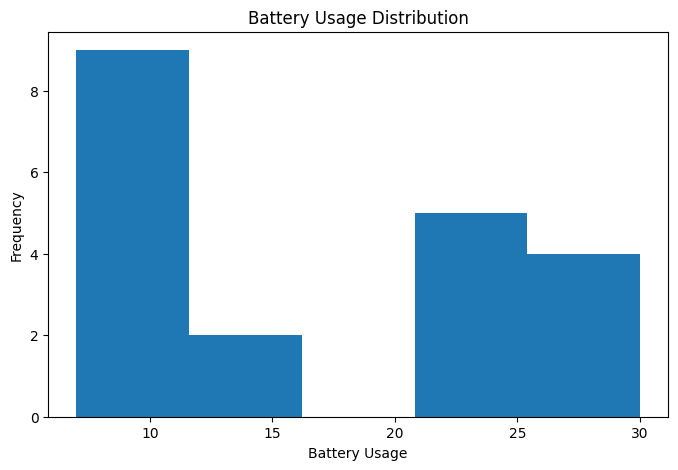

In [34]:
plt.figure(figsize=(8, 5))

plt.hist(df['Battery_Usage'], bins=5)

plt.title('Battery Usage Distribution')
plt.xlabel('Battery Usage')
plt.ylabel('Frequency')

plt.show()

In [36]:
print("Mean:", df['Battery_Usage'].mean())

print("Median:", df['Battery_Usage'].median())

print("Mode:", df['Battery_Usage'].mode()[0])

print("Variance:", df['Battery_Usage'].var())

print("Standard Deviation:", df['Battery_Usage'].std())

print("Range:", df['Battery_Usage'].max() - df['Battery_Usage'].min())

Mean: 16.75
Median: 12.0
Mode: 10.0
Variance: 69.25
Standard Deviation: 8.32165848854662
Range: 23.0


In [38]:
# Calculate Z-score standardization

df['Standardized_Battery'] = (
    df['Battery_Usage'] - df['Battery_Usage'].mean()
) / df['Battery_Usage'].std()

print(df[['Battery_Usage', 'Standardized_Battery']].head())

   Battery_Usage  Standardized_Battery
0           12.0             -0.570800
1           22.0              0.630884
2            8.0             -1.051473
3            7.0             -1.171641
4           23.0              0.751052


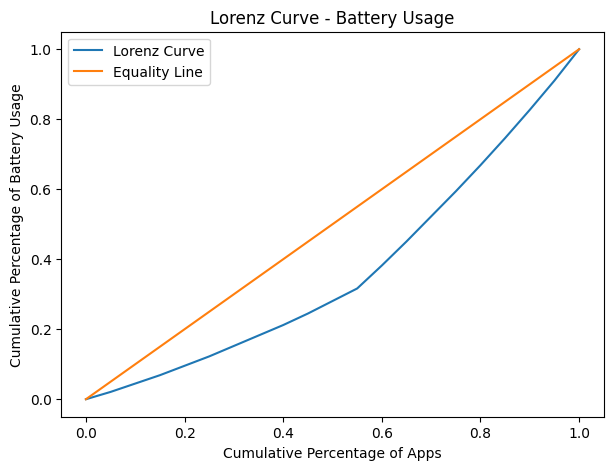

Gini Index: 0.266


In [40]:
# Sort battery usage in ascending order
battery = np.sort(df['Battery_Usage'])

# Calculate cumulative battery usage
cumulative = np.cumsum(battery)

# Calculate cumulative percentage
lorenz = cumulative / cumulative[-1]

# Add starting point
lorenz = np.insert(lorenz, 0, 0)

# Calculate population percentage
population = np.linspace(0, 1, len(lorenz))

# Plot Lorenz Curve
plt.figure(figsize=(7, 5))

plt.plot(population, lorenz, label='Lorenz Curve')
plt.plot([0, 1], [0, 1], label='Equality Line')

plt.title('Lorenz Curve - Battery Usage')
plt.xlabel('Cumulative Percentage of Apps')
plt.ylabel('Cumulative Percentage of Battery Usage')

plt.legend()
plt.show()

# Calculate Gini Index
gini = 1 - 2 * np.trapezoid(lorenz, population)

print("Gini Index:", round(gini, 3))

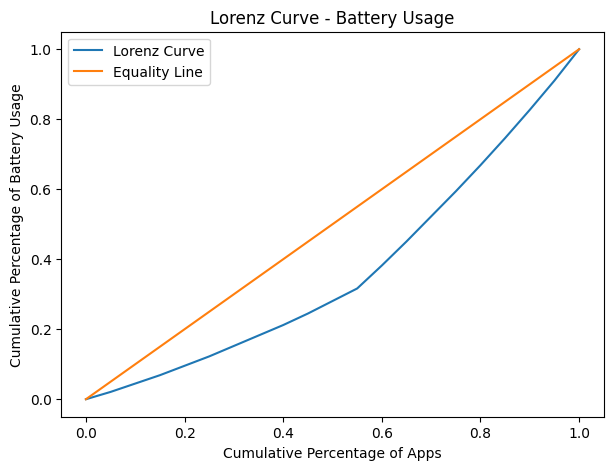

Gini Index: 0.266


In [42]:
# Sort battery usage in ascending order
battery = np.sort(df['Battery_Usage'])

# Calculate cumulative battery usage
cumulative = np.cumsum(battery)

# Calculate cumulative percentage
lorenz = cumulative / cumulative[-1]

# Add starting point
lorenz = np.insert(lorenz, 0, 0)

# Calculate population percentage
population = np.linspace(0, 1, len(lorenz))

# Plot Lorenz Curve
plt.figure(figsize=(7, 5))

plt.plot(population, lorenz, label='Lorenz Curve')
plt.plot([0, 1], [0, 1], label='Equality Line')

plt.title('Lorenz Curve - Battery Usage')
plt.xlabel('Cumulative Percentage of Apps')
plt.ylabel('Cumulative Percentage of Battery Usage')

plt.legend()
plt.show()

# Calculate Gini Index
gini = 1 - 2 * np.trapezoid(lorenz, population)

print("Gini Index:", round(gini, 3))

In [43]:
print("MOBILE BATTERY USAGE PATTERN ANALYSIS")
print("-------------------------------------")

print("Total Records:", len(df))
print("Total Apps:", df['App'].nunique())

print("\nHighest Battery Usage App:")
print(df.groupby('App')['Battery_Usage'].mean().idxmax())

print("\nLowest Battery Usage App:")
print(df.groupby('App')['Battery_Usage'].mean().idxmin())

print("\nAverage Battery Usage:", round(df['Battery_Usage'].mean(), 2))

print("\nGini Index:", round(gini, 3))

print("\nPROJECT COMPLETED SUCCESSFULLY!")

MOBILE BATTERY USAGE PATTERN ANALYSIS
-------------------------------------
Total Records: 20
Total Apps: 6

Highest Battery Usage App:
YouTube

Lowest Battery Usage App:
Chrome

Average Battery Usage: 16.75

Gini Index: 0.266

PROJECT COMPLETED SUCCESSFULLY!
